# Rekonstrukcja powierzchni 3D

## Cel i kolejność pracy

Zobaczysz, jak dane wejściowe wpływają na kształt mesha. W sekcjach 1–4 zaczynamy od chmury punktów i pomiarów głębi. W sekcji 5 wydobywamy powierzchnię z gęstości NeRF. W sekcji 6 sami wyznaczamy mapy głębi ze splatów i korzystamy ponownie z TSDF Fusion. Na końcu porównujemy te obserwacje z wynikami rekonstrukcji obiektów sfotografowanych w wielu widokach.

**Ćwiczenie na zajęciach** to [Próg gęstości NeRF](#prog-gestosci-nerf).

**Zadanie obowiązkowe** to [Głębokość piksela](#glebokosc-piksela). **Zadanie dodatkowe** to [Triangulacja mapy głębi](#triangulacja-mapy-glebi).

Żeby zacząć, otwórzcie notebook z katalogu repozytorium i uruchomcie komórki od góry. Wagi NeRF i skrypty znajdziecie w `data/` i `scripts/`. Wystarczy CPU.

In [1]:
import os

os.environ.setdefault("OPEN3D_DISABLE_WEB_VISUALIZER", "true")

import numpy as np
import open3d as o3d
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from scripts.utils.surface_reconstruction import (
    BG, BLUE, ORANGE, TEAL, mesh_index_update, mesh_trace, pixel_directions, point_trace,
    render_depth, scene_layout, style_figure, surface_panels, world_to_camera,
)

pio.renderers.default = "plotly_mimetype"
rng = np.random.default_rng(42)
o3d.utility.random.seed(42)

## 1. Rekonstrukcja mesha z chmury punktów

Próbkujemy powierzchnię pofałdowanego torusa. Open3D wyznacza normalne z lokalnych sąsiedztw i uzgadnia ich zwrot. Ball Pivoting łączy próbki trójkątami, a rekonstrukcja Poissona wyznacza gładką powierzchnię na podstawie zorientowanych punktów. [Dokumentacja Open3D](https://www.open3d.org/docs/latest/tutorial/geometry/surface_reconstruction.html)

In [2]:
reference = o3d.geometry.TriangleMesh.create_torus(
    torus_radius=0.89, tube_radius=0.28, radial_resolution=96, tubular_resolution=40,
)
vertices = np.asarray(reference.vertices)
x, y, z = vertices.T.copy()
angle = np.arctan2(y, x)
tube_scale = 1 + 0.18 * np.cos(3 * angle + 0.4)
radius = 0.89 + (np.hypot(x, y) - 0.89) * tube_scale
vertices[:] = np.column_stack((
    radius * np.cos(angle), radius * np.sin(angle),
    z * tube_scale + 0.14 * np.sin(3 * angle),
))
points = np.asarray(reference.sample_points_poisson_disk(5200).points).copy()
object_bounds = ((-1.32, 1.32), (-1.32, 1.32), (-0.57, 0.57))


def reconstruct(points):
    cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
    cloud.estimate_normals(o3d.geometry.KDTreeSearchParamKNN(knn=24))
    cloud.orient_normals_consistent_tangent_plane(k=24)

    ball = o3d.geometry.TriangleMesh.create_from_point_cloud_ball_pivoting(
        cloud, o3d.utility.DoubleVector([0.038, 0.065, 0.105]),
    )
    poisson, _ = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
        cloud, depth=7, n_threads=2,
    )
    return cloud, ball, poisson


def comparison(label, reconstruction):
    cloud, ball, poisson = reconstruction
    return [
        (label, point_trace(cloud.points)),
        ("Ball Pivoting", mesh_trace(ball.vertices, ball.triangles)),
        ("Poisson", mesh_trace(poisson.vertices, poisson.triangles, flat=False)),
    ]


clean = reconstruct(points)
cloud_figure = surface_panels(comparison("Chmura wejściowa", clean), 3, object_bounds, 320)
cloud_figure.show()

## 2. Wpływ jakości chmury punktów na rekonstrukcję

Dodajemy szum Gaussa o odchyleniu standardowym 1,7 cm w każdej osi albo usuwamy sektor torusa. Obie metody dostają w każdym wierszu te same punkty i normalne, a ustawienia rekonstrukcji są takie jak wyżej. W luce Ball Pivoting zostawia otwarte krawędzie, a Poisson domyka końce powierzchni.

In [3]:
noisy_points = points + rng.normal(0, 0.017, points.shape)
point_angle = np.arctan2(points[:, 1], points[:, 0])
gap_offset = (point_angle + 0.95 + np.pi) % (2 * np.pi) - np.pi
partial_points = points[np.abs(gap_offset) > 0.49]

noisy = reconstruct(noisy_points)
partial = reconstruct(partial_points)
quality_figure = surface_panels(
    comparison("Chmura z szumem", noisy) + comparison("Chmura z luką", partial),
    3, object_bounds, 590,
)
quality_figure.show()

## 3. Rekonstrukcja mesha z pojedynczej mapy głębi

Mapa głębi zapisuje dla każdego piksela głębokość pierwszej widocznej powierzchni mierzoną wzdłuż osi optycznej kamery. Znając parametry kamery, można z tych pomiarów odtworzyć punkty 3D. Pojedyncza mapa obejmuje tylko to, co widać z jednego ujęcia. W sekcji 4 połączymy mapy z kilku widoków, żeby odtworzyć także fragmenty zasłonięte w pojedynczym ujęciu.

Back-projection mnoży kierunek promienia przez głębokość $z$. Każdy kwadrat czterech sąsiednich pikseli daje dwa trójkąty. Trójkąt pozostaje, jeśli $\max(z_i)-\min(z_i)\leq\tau$. Zwiększ próg $\tau$ i obserwuj, kiedy pojawiają się połączenia między obiektami a tłem.

In [4]:
width, height = 96, 72
intrinsic = o3d.camera.PinholeCameraIntrinsic(
    width, height, 82, 82, (width - 1) / 2, (height - 1) / 2,
)
sphere = o3d.geometry.TriangleMesh.create_sphere(radius=0.57, resolution=48)
sphere.translate((-0.51, -0.10, 2.55))
box = o3d.geometry.TriangleMesh.create_box(width=0.78, height=0.84, depth=0.5)
box.translate((0.32, -0.37, 3.18))
wall = o3d.geometry.TriangleMesh.create_box(width=8, height=6, depth=0.1)
wall.translate((-4, -3, 4.8))
single_scene = o3d.t.geometry.RaycastingScene()
for shape in (sphere, box, wall):
    single_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(shape))

depth = render_depth(single_scene, intrinsic, np.eye(4))
depth_points = (pixel_directions(intrinsic) * depth[..., None]).reshape(-1, 3)
pixels = np.arange(depth.size, dtype=np.int32).reshape(depth.shape)
a, b = pixels[:-1, :-1].ravel(), pixels[:-1, 1:].ravel()
d, c = pixels[1:, :-1].ravel(), pixels[1:, 1:].ravel()
faces = np.column_stack((np.r_[a, b], np.r_[d, d], np.r_[b, c]))
face_depths = depth.ravel()[faces]
has_depth = (face_depths > 0).all(axis=1)
depth_jump = np.ptp(face_depths, axis=1)


def faces_at(threshold):
    return faces[has_depth & (depth_jump <= threshold)]

In [5]:
thresholds = (0.05, 0.10, 0.20, 0.40, 1.40, 1.80, 2.40, 3.00)
initial_step = 3
depth_figure = make_subplots(
    rows=1, cols=2, specs=[[{"type": "heatmap"}, {"type": "scene"}]],
    subplot_titles=("Mapa głębi", "Mesh po triangulacji"),
    column_widths=[0.40, 0.60], horizontal_spacing=0.13,
)
depth_figure.add_trace(go.Heatmap(
    z=depth, colorscale=[[0, BLUE], [0.5, BG], [1, ORANGE]],
    colorbar=dict(title="z [m]", x=0.39, xpad=2, len=0.72, thickness=12),
    hovertemplate="u=%{x}, v=%{y}<br>z=%{z:.2f} m<extra></extra>",
), row=1, col=1)
depth_figure.update_xaxes(title_text="u [px]")
depth_figure.update_yaxes(title_text="v [px]", autorange="reversed", scaleanchor="x")
depth_surface = mesh_trace(depth_points, faces_at(thresholds[initial_step]))
depth_surface.update(
    intensity=depth_points[:, 2].astype(np.float32), cmin=2.0, cmax=4.8,
    colorscale=[[0, TEAL], [1, "#9CCFC8"]], showscale=False,
)
depth_figure.add_trace(depth_surface, row=1, col=2)
depth_figure.update_scenes(**scene_layout(
    ((-2.85, 2.85), (-2.15, 2.15), (1.8, 5.0)), eye=(1.22, -0.93, -1.45), up=(0, -1, 0),
))

steps = []
for threshold in thresholds:
    steps.append(dict(
        label=f"{threshold:.2f}".replace(".", ","), method="restyle",
        args=[mesh_index_update(faces_at(threshold)), [1]],
    ))
style_figure(depth_figure, 510)
depth_figure.update_layout(
    sliders=[dict(active=initial_step, currentvalue=dict(prefix="Próg τ [m]  "),
                  steps=steps, x=0.15, len=0.75, pad=dict(t=52))],
    margin=dict(b=85),
)
depth_figure.show()

<a id="triangulacja-mapy-glebi" name="triangulacja-mapy-glebi"></a>

### Zadanie dodatkowe - Triangulacja mapy głębi

Dobierz próg różnicy głębokości, który ogranicza fałszywe połączenia kuli i prostopadłościanu ze ścianą w tle. Sprawdź przy tym, czy po zmianie progu w meshu pojawiają się ubytki na powierzchni któregoś z obiektów.

1. Na suwaku **Próg τ [m]** ustaw kolejno **0,10 m** i **2,40 m**. Porównaj połączenia ze ścianą i podaj liczbę trójkątów dla obu ustawień, korzystając z `len(faces_at(prog))`.
2. Wybierz próg z suwaka. Podaj jego wartość w metrach i krótko uzasadnij wybór tym, co widać na meshu. Możesz sprawdzić też wartości pośrednie.

## 4. TSDF Fusion

Obserwujemy ten sam torus z 16 pozycji nad i pod obiektem. Wszystkie kamery mają te same parametry wewnętrzne. Dla środka kamery $C$ i macierzy obrotu $R$ używamy $p_\mathrm{cam}=R(p_\mathrm{world}-C)$. Tę samą transformację przekazujemy do renderowania mapy i integracji Open3D. Do wspólnej siatki TSDF o wokselach 2,5 cm dokładamy kolejne obserwacje, a mesh odczytujemy po 1, 4, 8 i 16 ujęciach. [Integracja RGB-D w Open3D](https://www.open3d.org/docs/latest/tutorial/pipelines/rgbd_integration.html)

In [6]:
fusion_scene = o3d.t.geometry.RaycastingScene()
fusion_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(reference))
fusion_intrinsic = o3d.camera.PinholeCameraIntrinsic(128, 112, 116, 116, 63.5, 55.5)
azimuths = np.arange(-55, 305, 90)
angles = [(a + offset, e) for offset in (0, 45) for e in (30, -30) for a in azimuths]

integration = o3d.pipelines.integration
volume = integration.UniformTSDFVolume(
    length=3.2, resolution=128, origin=np.full(3, -1.6), sdf_trunc=0.075,
    color_type=integration.TSDFVolumeColorType.NoColor,
)
image_shape = (fusion_intrinsic.height, fusion_intrinsic.width)
dummy_color = o3d.geometry.Image(np.zeros((*image_shape, 3), dtype=np.uint8))
poses, depth_maps, snapshots = [], [], {}
for count, (azimuth, elevation) in enumerate(angles, start=1):
    az, el = np.deg2rad([azimuth, elevation])
    eye = 3.55 * np.array([np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), np.sin(el)])
    extrinsic = world_to_camera(eye)
    depth_map = render_depth(fusion_scene, fusion_intrinsic, extrinsic)
    poses.append(extrinsic)
    depth_maps.append(depth_map)
    rgbd = o3d.geometry.RGBDImage.create_from_color_and_depth(
        dummy_color, o3d.geometry.Image(depth_map), depth_scale=1.0,
        depth_trunc=6.0, convert_rgb_to_intensity=False,
    )
    volume.integrate(rgbd, fusion_intrinsic, extrinsic)
    if count in (1, 4, 8, 16):
        snapshots[count] = volume.extract_triangle_mesh()

labels = {1: "1 mapa głębi", 4: "4 mapy głębi", 8: "8 map głębi", 16: "16 map głębi"}
fusion_figure = surface_panels(
    [(labels[count], mesh_trace(mesh.vertices, mesh.triangles, flat=False))
     for count, mesh in snapshots.items()],
    2, object_bounds, 640,
)
fusion_figure.update_scenes(camera_eye=dict(x=1.08, y=-1.45, z=-0.65))
fusion_figure.show()

## 5. Mesh z NeRF

Wytrenowany NeRF zwraca w położeniu $\mathbf{x}$ gęstość $\sigma(\mathbf{x})$, która mówi, jak silnie światło jest tłumione w pobliżu tego miejsca. SDF z notebooka 01 opisuje odległość ze znakiem i ma wyróżniony poziom zero. Dla gęstości sami wybieramy próg $\tau$, traktujemy $\sigma\ge\tau$ jako wnętrze i szukamy granicy $\sigma(\mathbf{x})=\tau$. [Mildenhall i in., 2020, §4](https://arxiv.org/abs/2003.08934) i [ekstrakcja mesha w kodzie autorów](https://github.com/bmild/nerf/blob/master/extract_mesh.ipynb).

**Od pola do trójkątów.** Najpierw pytamy sieć o gęstość w węzłach regularnej siatki. W sześcianie, w którym są próbki po obu stronach progu, dzielimy komórkę na sześć tetraedrów. Na ich krawędziach interpolujemy położenie przecięć i łączymy przecięcia w trójkąty. To ten sam pomysł co wyszukiwanie przecięć w Marching Cubes, zastosowany do prostszych komórek. [Doi i Koide, 1991](https://globals.ieice.org/en_transactions/information/10.1587/e74-d_1_214/_p).

**Co zobaczysz.** Mała sieć została wytrenowana na 72 syntetycznych widokach RGB torusa. Przekrój pokazuje gęstość i kontur geometrii odniesienia, a obok widać mesh wybranego progu. Geometria odniesienia służy do porównania po treningu. Przy zmianie progu używamy tych samych wag i próbek. Własne wykresy i dane demonstracyjne. [Skrypt treningu](scripts/generate_figures/train_torus_nerf.py).

In [7]:
from functools import lru_cache
from itertools import permutations, product
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm, to_rgb
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

INK, SECONDARY, GRAY, GRID = "#0F172A", "#64748B", "#94A3B8", "#CBD5E1"
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "mathtext.fontset": "dejavusans",
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "text.color": INK,
        "axes.labelcolor": INK,
        "axes.edgecolor": GRAY,
        "axes.titlecolor": INK,
        "xtick.color": SECONDARY,
        "ytick.color": SECONDARY,
        "grid.color": GRID,
        "figure.dpi": 115,
    }
)


def show(fig):
    display(fig)
    plt.close(fig)


def controls(function, **parameters):
    output = widgets.interactive_output(function, parameters)
    row = widgets.HBox(list(parameters.values()), layout=widgets.Layout(flex_flow="row wrap"))
    display(widgets.VBox([row, output]))

In [8]:
def extract_density_surface(field, axis, level):
    corners = np.array(list(product((0, 1), repeat=3)))
    stop = np.array(field.shape) - 1
    origin = np.indices(stop).reshape(3, -1).T
    samples = tuple((origin[:, None, :] + corners).transpose(2, 0, 1))
    signs = field[samples] < level
    active = signs.any(axis=1) & ~signs.all(axis=1)
    grid = np.ravel_multi_index(samples, field.shape)[active]
    vertices = []
    faces = []
    edge_vertices = {}
    values = field.ravel()

    def crossing(a, b):
        edge = tuple(sorted((int(a), int(b))))
        if edge not in edge_vertices:
            pa, pb = np.array(np.unravel_index(edge, field.shape)).T
            va, vb = values[list(edge)]
            t = (level - va) / (vb - va)
            edge_vertices[edge] = len(vertices)
            vertices.append(axis[pa] + t * (axis[pb] - axis[pa]))
        return edge_vertices[edge]

    # Sześć tetraedrów ze wspólną przekątną 000–111.
    tetrahedra = [[0, 1 << i, (1 << i) | (1 << j), 7] for i, j, _ in permutations(range(3))]
    for tetra in tetrahedra:
        ids = grid[:, tetra]
        inside = values[ids] < level
        cut = inside.any(axis=1) & ~inside.all(axis=1)
        for row, mask in zip(ids[cut], inside[cut]):
            negative, positive = row[mask], row[~mask]
            if len(negative) == 1 or len(positive) == 1:
                tip, base = (negative, positive) if len(negative) == 1 else (positive, negative)
                triangles = [[crossing(tip[0], a) for a in base]]
            else:
                a, b = negative
                c, d = positive
                ac, ad, bc, bd = crossing(a, c), crossing(a, d), crossing(b, c), crossing(b, d)
                triangles = [[ac, ad, bc], [ad, bd, bc]]

            pos = np.array(np.unravel_index(positive, field.shape)).mean(axis=1)
            neg = np.array(np.unravel_index(negative, field.shape)).mean(axis=1)
            for triangle in triangles:
                p, q, r = (vertices[i] for i in triangle)
                if np.dot(np.cross(q - p, r - p), pos - neg) < 0:
                    triangle.reverse()
                faces.append(triangle)
    if not faces:
        return np.empty((0, 3)), np.empty((0, 3), dtype=int)
    return np.asarray(vertices), np.asarray(faces)

In [9]:
def field_features(positions):
    frequencies = np.pi * np.array([1, 2, 4], dtype=np.float32)
    angles = positions[..., None] * frequencies
    shape = (*positions.shape[:-1], 9)
    return np.concatenate(
        (positions, np.sin(angles).reshape(shape), np.cos(angles).reshape(shape)), axis=-1
    )


def query_density(positions, layers):
    features = field_features(positions)
    for weights, bias in layers[:-1]:
        features = np.maximum(features @ weights.T + bias, 0)
    weights, bias = layers[-1]
    return np.logaddexp(0, features @ weights[0] + bias[0] - 2)


with np.load(Path("data/torus_nerf_weights.npz"), allow_pickle=False) as saved:
    layers = [(saved[f"w{i}"], saved[f"b{i}"]) for i in range(4)]
axis = np.linspace(-1.32, 1.32, 45, dtype=np.float32)
coordinates = np.stack(np.meshgrid(axis, axis, axis, indexing="ij"), axis=-1)
density = query_density(coordinates, layers)
middle = axis.size // 2
reference_slice = (
    fusion_scene.compute_signed_distance(o3d.core.Tensor(coordinates[:, :, middle, :])).numpy().T
)


@lru_cache(maxsize=20)
def density_mesh(threshold):
    # Ekstraktor klasyfikuje wnętrze po stronie ujemnej.
    return extract_density_surface(-density, axis, -threshold)

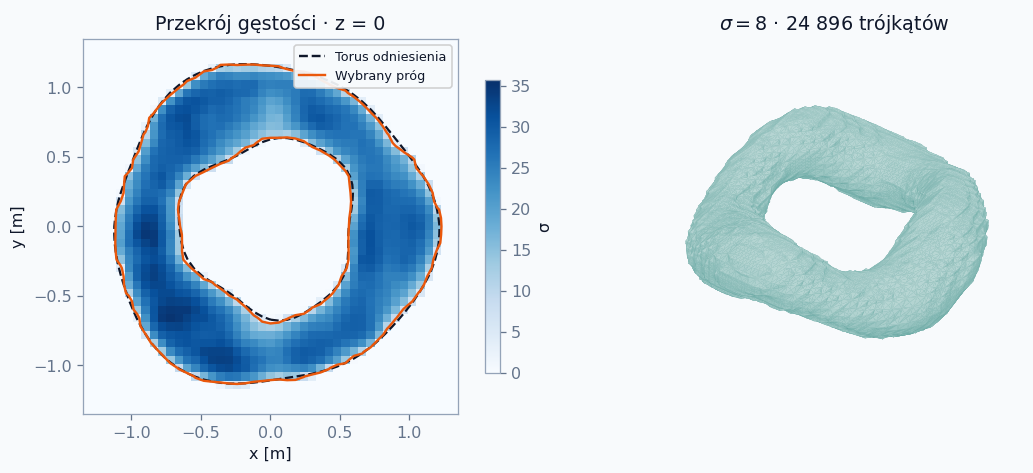

In [10]:
def mesh_picture(ax, vertices, faces, title, azimuth=-57):
    if len(faces):
        triangles = vertices[faces]
        a, b, c = triangles.transpose(1, 0, 2)
        normals = np.cross(b - a, c - a)
        normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
        light = np.array([0.30, -0.48, 0.82])
        factor = 0.18 + 0.52 * (np.clip(normals @ light, -1, 1) + 1) / 2
        shade = np.asarray(to_rgb(TEAL)) * (1 - factor[:, None]) + factor[:, None]
        ax.add_collection3d(
            Poly3DCollection(triangles, facecolors=shade, edgecolors=shade, linewidths=0.10)
        )
    else:
        ax.text2D(0.5, 0.5, "Brak powierzchni w siatce", ha="center", transform=ax.transAxes)
    ax.set(xlim=(-1.32, 1.32), ylim=(-1.32, 1.32), zlim=(-0.72, 0.72), title=title)
    ax.set_box_aspect((2.64, 2.64, 1.44), zoom=1.3)
    ax.view_init(elev=40, azim=azimuth)
    ax.set_axis_off()


def nerf_figure(threshold=8, azimuth=-57):
    fig = plt.figure(figsize=(10.4, 4), layout="constrained")
    ax = fig.add_subplot(121)
    section = density[:, :, middle].T
    image = ax.pcolormesh(
        axis, axis, section, shading="nearest", cmap="Blues", vmin=0, vmax=density.max()
    )
    ax.contour(
        axis, axis, reference_slice, levels=[0], colors=[INK], linestyles=["--"], linewidths=1.4
    )
    ax.plot([], [], "--", color=INK, label="Torus odniesienia")
    if section.min() < threshold < section.max():
        ax.contour(axis, axis, section, levels=[threshold], colors=[ORANGE], linewidths=1.5)
        ax.plot([], [], color=ORANGE, label="Wybrany próg")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.92)
    ax.set(xlabel="x [m]", ylabel="y [m]", title="Przekrój gęstości · z = 0", aspect="equal")
    fig.colorbar(image, ax=ax, shrink=0.78, label="σ")
    vertices, faces = density_mesh(threshold)
    mesh_picture(
        fig.add_subplot(122, projection="3d"),
        vertices,
        faces,
        rf"$\sigma={threshold:g}$ · {len(faces):,} trójkątów".replace(",", " "),
        azimuth,
    )
    return fig


def nerf_levels_figure(levels):
    fig = plt.figure(figsize=(10.8, 3.3), layout="constrained")
    for i, t in enumerate(levels, 1):
        mesh_picture(
            fig.add_subplot(1, len(levels), i, projection="3d"), *density_mesh(t), rf"$\tau={t:g}$"
        )
    return fig


def show_nerf(threshold=8, azimuth=-57):
    show(nerf_figure(threshold, azimuth))


controls(
    show_nerf,
    threshold=widgets.IntSlider(
        description="Próg σ",
        min=1,
        max=max(22, int(density.max()) + 2),
        value=8,
        continuous_update=False,
    ),
    azimuth=widgets.IntSlider(
        description="Obrót", min=-180, max=180, value=-57, continuous_update=False
    ),
)

<a id="prog-gestosci-nerf" name="prog-gestosci-nerf"></a>

### Ćwiczenie na zajęciach. Próg gęstości NeRF

Zmienimy próg i zobaczymy, co się stanie z kształtem tego samego torusa. Zanim ruszycie suwakiem, zastanówcie się, co wyższy próg zrobi z cieńszymi częściami pierścienia.

1. Ustawcie kolejno `2`, `8` i `30` na suwaku **Próg σ**. Zostawcie ten sam obrót, żeby łatwiej porównać wyniki. Przy którym progu pierścień pozostaje w całości? Jak blisko przerywanej linii wypada kontur na przekroju `z = 0`?
2. Uruchomcie komórkę poniżej, żeby zobaczyć, z ilu części składa się mesh przy każdym progu. Dwa trójkąty liczą się jako połączone, jeśli mają wspólną krawędź.

Który próg wybralibyście dla tego torusa? Uzasadnijcie wybór tym, co widać w przekroju i w meshu. Zastanówcie się, czy dwa meshe o tej samej liczbie części mogą mieć różną jakość.

In [ ]:
for threshold in (2, 8, 30):
    mesh_vertices, mesh_faces = density_mesh(threshold)
    mesh = o3d.geometry.TriangleMesh(
        o3d.utility.Vector3dVector(mesh_vertices),
        o3d.utility.Vector3iVector(mesh_faces),
    )
    _, components, _ = mesh.cluster_connected_triangles()
    print(f"Próg {threshold:2d} | Liczba spójnych fragmentów: {len(components)}")

## 6. Mesh z Gaussian Splatting

**Od koloru do odległości.** Na jednym pikselu kilka splatów może nakładać się na siebie. Przechodzimy od najbliższego do najdalszego. Splat z przodu może zasłonić część wkładu tych dalszych. $T_i$ to część transmisji, która została przed splatem $i$, a $\alpha_i$ to jego lokalna opacity w tym pikselu. [Kerbl i in., 2023, §4](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/).

$$T_i=\prod_{j<i}(1-\alpha_j),\qquad w_i=T_i\alpha_i,\qquad A_\mathrm{px}=\sum_i w_i.$$

W naszej demonstracji $z_i$ to głębokość środka splatu wzdłuż osi optycznej kamery. Głębokość piksela szacujemy ze średniej ważonej, żeby później połączyć obserwacje z różnych widoków. [Huang i in. (2024), równanie 18 w dodatku A](https://surfsplatting.github.io/assets/paper/paper.pdf) opisują tę zasadę ważenia dla głębokości obliczanych w miejscach przecięcia promienia z dyskami.

$$D=\frac{\sum_i w_i z_i}{A_\mathrm{px}},\qquad A_\mathrm{px}>0.$$

Jeśli pierwszy splat jest całkowicie kryjący, dalsze splaty mają wagę zero. Jeśli widzimy dwie warstwy, średnia może wypaść w pustej przestrzeni nawet przy wysokiej łącznej opacity. Dla $A_\mathrm{px}=0$ głębokość jest nieokreślona. Sprawdź to na poniższym schemacie autorów laboratorium dwóch splatów, a potem przetestuj skutki na mapie głębi torusa. W torusie położenia, rozmiary i opacity splatów ustawiamy w kodzie.

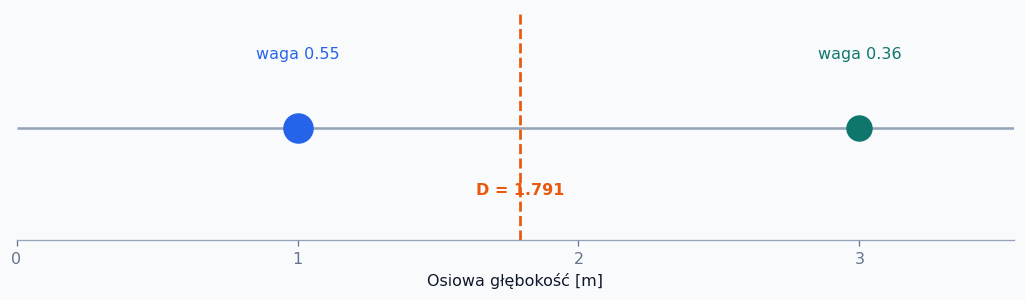

In [11]:
def two_splat_figure(front_alpha=0.55):
    z = np.array([1.0, 3.0])
    weights = np.array([front_alpha, (1 - front_alpha) * 0.8])
    estimate = weights @ z / weights.sum()
    fig, ax = plt.subplots(figsize=(8.8, 2.5), layout="constrained")
    ax.hlines(0, 0, 3.55, color=GRAY, lw=1.6)
    ax.axvline(estimate, color=ORANGE, linestyle="--", lw=1.7)
    for x, weight, color in zip(z, weights, (BLUE, TEAL)):
        ax.scatter(x, 0, s=80 + 450 * weight, color=color, zorder=3)
        ax.text(x, 0.29, f"waga {weight:.2f}", ha="center", color=color)
    ax.text(estimate, -0.28, f"D = {estimate:.3f}", ha="center", color=ORANGE, weight="bold")
    ax.set(
        xlim=(0, 3.55),
        ylim=(-0.47, 0.49),
        yticks=[],
        xticks=[0, 1, 2, 3],
        xlabel="Osiowa głębokość [m]",
    )
    for key in ("left", "right", "top"):
        ax.spines[key].set_visible(False)
    return fig


def show_ray(front_alpha=0.55):
    show(two_splat_figure(front_alpha))


controls(
    show_ray,
    front_alpha=widgets.FloatSlider(
        description="Opacity z przodu",
        min=0,
        max=1,
        step=0.05,
        value=0.55,
        continuous_update=False,
    ),
)

In [12]:
# Wejście z sekcji 1. Rozmiary splatów podajemy w jednostkach sceny.
gs_centers = np.asarray(clean[0].points)[::3].copy()
gs_normals = np.asarray(clean[0].normals)[::3].copy()
gs_normals /= np.maximum(np.linalg.norm(gs_normals, axis=1, keepdims=True), 1e-12)
normal_outer = np.einsum("ni,nj->nij", gs_normals, gs_normals)
tangent_scale, normal_scale = 0.061, 0.014
gs_cov = tangent_scale**2 * np.eye(3) + (normal_scale**2 - tangent_scale**2) * normal_outer
gs_opacity = np.full(len(gs_centers), 0.85)

In [13]:
def gs_depth_pinhole(centers, covariances, opacity, intrinsic, extrinsic):
    """Zwraca estymatę osiowej głębokości Z i łączną opacity dla kamery z sekcji 4."""
    fx, fy = intrinsic.get_focal_length()
    cx, cy = intrinsic.get_principal_point()
    height, width = intrinsic.height, intrinsic.width
    rotation = extrinsic[:3, :3]
    camera_xyz = centers @ rotation.T + extrinsic[:3, 3]
    remaining = np.ones((height, width))
    weighted_z = np.zeros_like(remaining)
    for i in np.argsort(camera_xyz[:, 2]):
        x, y, z = camera_xyz[i]
        if z <= 0:
            continue
        u, v = fx * x / z + cx, fy * y / z + cy
        jacobian = np.array([[fx / z, 0, -fx * x / z**2], [0, fy / z, -fy * y / z**2]])
        projection = jacobian @ rotation
        covariance_2d = projection @ covariances[i] @ projection.T + 0.25 * np.eye(2)
        ru, rv = 3 * np.sqrt(np.diag(covariance_2d))
        x0, x1 = max(0, int(np.floor(u - ru))), min(width, int(np.ceil(u + ru)) + 1)
        y0, y1 = max(0, int(np.floor(v - rv))), min(height, int(np.ceil(v + rv)) + 1)
        if x1 <= x0 or y1 <= y0:
            continue
        yy, xx = np.mgrid[y0:y1, x0:x1]
        delta = np.stack((xx - u, yy - v), axis=-1)
        d2 = np.einsum("...i,ij,...j->...", delta, np.linalg.inv(covariance_2d), delta)
        alpha = np.where(d2 <= 9, opacity[i] * np.exp(-0.5 * d2), 0)
        patch = np.s_[y0:y1, x0:x1]
        weight = remaining[patch] * alpha
        weighted_z[patch] += weight * z
        remaining[patch] *= 1 - alpha
    coverage = 1 - remaining
    depth = np.divide(weighted_z, coverage, out=np.zeros_like(weighted_z), where=coverage > 1e-8)
    return depth.astype(np.float32), coverage

### Mapa głębi ze splatów

Dla tej samej kamery porównujemy głębię pierwszego trafienia w mesh torusa z głębią oszacowaną przez splaty. Mapy mają wspólną skalę. Mapa błędu pokazuje $D_\mathrm{splat}-D_\mathrm{ref}$ tylko tam, gdzie obie metody zwracają głębokość. Wykresy opracowaliśmy na danych demonstracyjnych.

**Po co maska?** Gauss wnosi wkład także obok swojego środka. Na brzegu obiektu splat może pokryć piksel, w którym promień mija obiekt. Odrzucamy piksele poniżej progu $A_\mathrm{px}$. Podniesienie progu może usunąć fałszywe pomiary tła i poprawne pomiary brzegu. Oba efekty sprawdzicie w zadaniu [Głębokość piksela](#glebokosc-piksela).

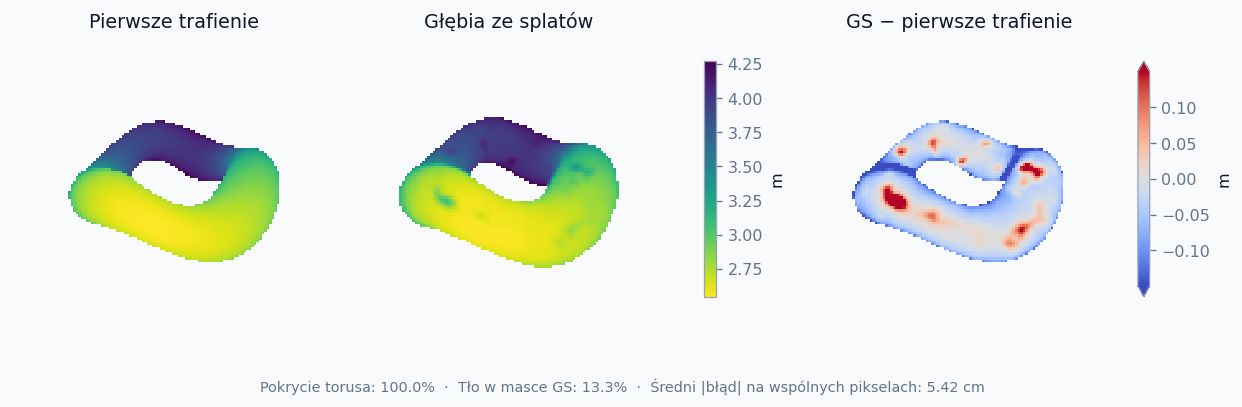

In [14]:
gs_views = [
    gs_depth_pinhole(gs_centers, gs_cov, gs_opacity, fusion_intrinsic, pose) for pose in poses
]


def depth_figure(view=0, cutoff=0.72):
    estimate, coverage = gs_views[view]
    target = depth_maps[view]
    accepted = (estimate > 0) & (coverage >= cutoff)
    overlap = accepted & (target > 0)
    delta = np.where(overlap, estimate - target, np.nan)
    fig, panels = plt.subplots(1, 3, figsize=(10.7, 3.62), layout="constrained")
    valid = target[target > 0]
    limit = 0.15
    for ax, data, title in zip(
        panels[:2],
        (np.where(target > 0, target, np.nan), np.where(accepted, estimate, np.nan)),
        ("Pierwsze trafienie", "Głębia ze splatów"),
    ):
        shared = ax.imshow(
            data, cmap="viridis_r", vmin=valid.min(), vmax=valid.max(), interpolation="nearest"
        )
        ax.set_title(title)
    err = panels[2].imshow(
        delta, cmap="coolwarm", norm=TwoSlopeNorm(0, -limit, limit), interpolation="nearest"
    )
    panels[2].set_title("GS − pierwsze trafienie")
    fig.colorbar(shared, ax=panels[:2].tolist(), shrink=0.62, label="m")
    fig.colorbar(err, ax=panels[2], shrink=0.62, label="m", extend="both")
    for ax in panels:
        ax.set_axis_off()
    mae = np.abs(delta[overlap]).mean() if overlap.any() else float("nan")
    background = (accepted & (target == 0)).sum() / max(1, accepted.sum())
    fig.supxlabel(
        f"Pokrycie torusa: {overlap.sum()/len(valid):.1%}  ·  "
        f"Tło w masce GS: {background:.1%}  ·  "
        f"Średni |błąd| na wspólnych pikselach: {100*mae:.2f} cm",
        color=SECONDARY,
        fontsize=9,
    )
    return fig


def show_depth(view=0, cutoff=0.72):
    show(depth_figure(view, cutoff))


controls(
    show_depth,
    view=widgets.IntSlider(
        description="Widok", min=0, max=len(poses) - 1, value=0, continuous_update=False
    ),
    cutoff=widgets.SelectionSlider(
        description="Próg opacity", options=[0.55, 0.72, 0.90, 0.99], value=0.72, continuous_update=False
    ),
)

### Fuzja TSDF

Jeden widok dostarcza pomiarów od strony kamery. Znając parametry kamer i ich pozy, osadzamy pomiary we wspólnej siatce 3D. Każda mapa aktualizuje wartości pola przy zaobserwowanej powierzchni, a mesh odczytujemy na poziomie zero. Więcej widoków może uzupełnić brakujące strony torusa. Zgodne przesunięcie pomiarów głębi może przejść na mesh także po fuzji. [Curless i Levoy, 1996](https://graphics.stanford.edu/papers/volrange/) i [implementacja RGB-D w Open3D](https://www.open3d.org/docs/latest/tutorial/pipelines/rgbd_integration.html).

Porównujemy głębię pierwszego trafienia i głębię ze splatów przy tych samych kamerach, wokselach i parametrach fuzji. Zmieniaj jedną rzecz naraz. Ustaw 4 i 16 widoków przy tym samym progu opacity, a potem przy 16 widokach zmień sam próg. Zwróć uwagę na brzegi, ubytki i kształt otworu. Wykresy opracowaliśmy na danych demonstracyjnych.

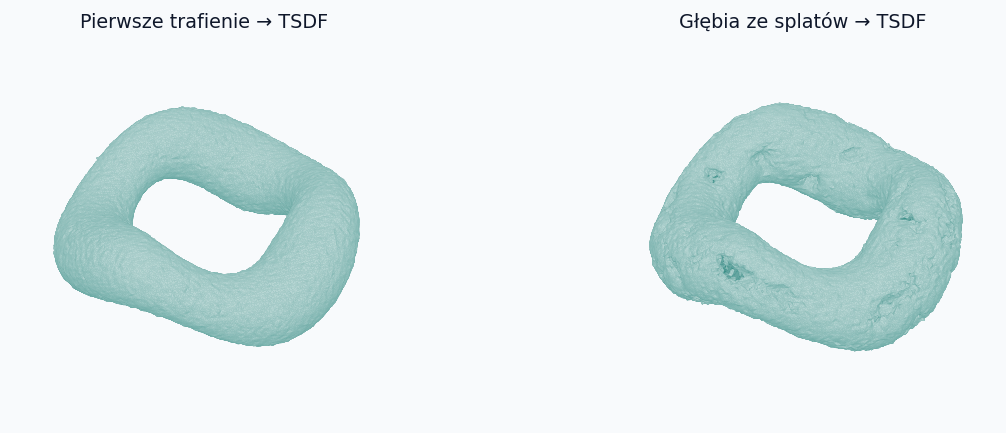

In [15]:
@lru_cache(maxsize=12)
def fuse_splat_depth(count=16, cutoff=0.72):
    gs_volume = integration.UniformTSDFVolume(
        length=volume.length,
        resolution=volume.resolution,
        origin=np.full(3, -volume.length / 2),
        sdf_trunc=volume.sdf_trunc,
        color_type=volume.color_type,
    )
    for (estimate, coverage), pose in zip(gs_views[:count], poses[:count]):
        masked_depth = np.where(coverage >= cutoff, estimate, 0).astype(np.float32)
        rgbd = o3d.geometry.RGBDImage.create_from_color_and_depth(
            dummy_color,
            o3d.geometry.Image(masked_depth),
            depth_scale=1.0,
            depth_trunc=6.0,
            convert_rgb_to_intensity=False,
        )
        gs_volume.integrate(rgbd, fusion_intrinsic, pose)
    return gs_volume.extract_triangle_mesh()


def gs_mesh_figure(count=16, cutoff=0.72, azimuth=-57):
    fig = plt.figure(figsize=(10.4, 3.65), layout="constrained")
    for i, (mesh, label) in enumerate(
        (
            (snapshots[count], "Pierwsze trafienie → TSDF"),
            (fuse_splat_depth(count, cutoff), "Głębia ze splatów → TSDF"),
        ),
        1,
    ):
        mesh_picture(
            fig.add_subplot(1, 2, i, projection="3d"),
            np.asarray(mesh.vertices),
            np.asarray(mesh.triangles),
            label,
            azimuth,
        )
    return fig


def show_gs_mesh(count=16, cutoff=0.72, azimuth=-57):
    show(gs_mesh_figure(count, cutoff, azimuth))


controls(
    show_gs_mesh,
    count=widgets.SelectionSlider(
        description="Widoki", options=list(snapshots), value=16, continuous_update=False
    ),
    cutoff=widgets.SelectionSlider(
        description="Próg opacity", options=[0.55, 0.72, 0.9], value=0.72, continuous_update=False
    ),
    azimuth=widgets.IntSlider(
        description="Obrót", min=-180, max=180, value=-57, continuous_update=False
    ),
)

<a id="glebokosc-piksela" name="glebokosc-piksela"></a>

### Zadanie obowiązkowe - Głębokość piksela

Wróćmy do dwóch splatów ze slajdu 33. Sprawdźcie, jak dalszy splat wpływa na głębię piksela, a potem zobaczcie, co można zauważyć na całej mapie głębi. Skrót znajdziecie na slajdzie 38. To jedno z dwóch zadań, które wszyscy wykonują zgodnie z wykazem w README.

1. Jak myślicie, przy której z wartości `alpha[0]` w komórce poniżej głębia wypadnie między splatami? Uzupełnijcie dwa `TODO` w `pixel_depth` i uruchomcie komórkę, żeby sprawdzić wynik. Gdy suma wag wynosi zero, głębia ma być `NaN`.
2. Wróćcie do **Mapy głębi ze splatów**. Zostawcie `Widok = 0` i ustawcie próg opacity najpierw na `0.55`, potem na `0.99`. Przy każdym progu zapiszcie pokrycie torusa i udział tła w masce. Obie liczby są pod wykresem.
3. Który próg odrzucił więcej tła? Czy przy okazji zniknęła część torusa? Zastanówcie się, kiedy nawet piksel o wysokiej opacity może mieć błędną głębię i gdzie zobaczylibyście taki błąd w meshu.

In [ ]:
def pixel_depth(z, alpha):
    transmission = np.r_[1.0, np.cumprod(1 - alpha[:-1])]
    weights = None  # TODO 1. Połącz transmission i alpha element po elemencie.
    if weights is None:
        return None, None
    total_alpha = weights.sum()
    if total_alpha == 0:
        return weights, np.nan
    depth = None  # TODO 2. Oblicz znormalizowaną średnią ważoną głębokości z.
    return weights, depth


z = np.array([1.0, 3.0])
for front_alpha in (0.0, 0.60, 1.0):
    alpha = np.array([front_alpha, 0.75])
    w, d = pixel_depth(z, alpha)
    if d is None:
        print("Uzupełnij oba TODO.")
        break
    expected_w = np.array([front_alpha, (1 - front_alpha) * 0.75])
    assert np.allclose(w, expected_w), "Sprawdź osłabienie drugiego splatu."
    assert np.isclose(d, expected_w @ z / expected_w.sum()), "Sprawdź normalizację."
    print(f"α pierwszego = {front_alpha:.2f}   w = {w}   D = {d:.3f}")
else:
    empty_weights, empty_depth = pixel_depth(z, np.zeros_like(z))
    assert np.allclose(empty_weights, 0) and np.isnan(empty_depth)
    print("Wszystkie przypadki przeszły autosprawdzenie.")

### Rzeczywiste obiekty. 3DGS, SuGaR i 2DGS

Zobaczmy teraz, jak te różnice wyglądają na zdjęciach prawdziwych przedmiotów. Na rysunku 3 wybierzcie detal z fotografii po prawej, np. krawędź narzędzia lub przerwę między owocami. Poszukajcie go w meshach `3DGS`, `SuGaR` i `2DGS`. Czy w którejś wersji krawędź jest poszarpana albo dwa elementy zlewają się ze sobą? Mesh oznaczony `3DGS` pochodzi z eksperymentu porównawczego autorów. [Zhang, Liu i Han, 2024, rys. 3, str. 7 PDF](https://papers.neurips.cc/paper_files/paper/2024/file/b8b34328ae68ccc931265bcd21ae5f16-Paper-Conference.pdf#page=7).

- **SuGaR** podczas optymalizacji zachęca Gaussy do ułożenia się wzdłuż powierzchni. Następnie pobiera z niej próbki z normalnymi i buduje mesh metodą Poissona. Zobaczcie render i mesh bez tekstury w sekcji **Kitchen** na [stronie projektu SuGaR](https://anttwo.github.io/sugar/).
- **2DGS** używa zorientowanych dysków w 3D. Głębię poszczególnych splatów określa przecięcie promienia z ich płaszczyzną. W fuzji TSDF używa głębi medianowej. Przewińcie do *Geometry Reconstruction*, gdzie autorzy pokazują wyniki 3DGS i 2DGS. [Huang i in., 2024](https://surfsplatting.github.io/).

Który fragment mesha obejrzelibyście jeszcze z innej strony, żeby sprawdzić, jak dobrze odtworzono kształt?

### Eksport mesha

Ustaw `EXPORT_MESH = True`, aby zapisać mesh z fuzji 16 widoków. W notebooku 03 możesz wczytać ten plik zamiast chorągiewki.

In [17]:
EXPORT_MESH = False
if EXPORT_MESH:
    gs_mesh = fuse_splat_depth()
    np.savez_compressed(
        "mesh_gs.npz", vertices=np.asarray(gs_mesh.vertices), faces=np.asarray(gs_mesh.triangles)
    )
    print("Zapisano mesh_gs.npz")

## Podsumowanie rekonstrukcji

| Wejście | Jak otrzymujemy mesh | Co może zmienić wynik |
| --- | --- | --- |
| Chmura punktów | Trójkąty między próbkami albo rekonstrukcja pola z punktów i normalnych | Luki, szum i rozkład próbek |
| Mapy głębi | Triangulacja sąsiednich pikseli lub fuzja TSDF z wielu widoków | Granice głębokości, dokładność map i pokrycie kamerami |
| Gęstość NeRF | Izopowierzchnia $\sigma=\tau$ z próbek pola | Próg i rozdzielczość próbkowania |
| Gaussian Splatting | Głębia dla każdego widoku, maska opacity i fuzja TSDF | Mieszanie warstw, brzeg sylwetki i niespójność między widokami |

W SDF powierzchnia ma zdefiniowany poziom zero, a znak rozróżnia wnętrze i zewnętrze, jeśli powierzchnia ma dobrze określone obie strony. To wygodne do ekstrakcji i operacji na kształtach. Z samych zdjęć trzeba jednak jeszcze estymować geometrię, szczególnie w obszarach słabo widocznych. NeRF i 3DGS zawierają informacje o wyglądzie potrzebne do renderowania nowych widoków, w tym efektów zależnych od kierunku obserwacji. [Park i in., 2019](https://openaccess.thecvf.com/content_CVPR_2019/html/Park_DeepSDF_Learning_Continuous_Signed_Distance_Functions_for_Shape_Representation_CVPR_2019_paper.html), [Mildenhall i in., 2020](https://www.matthewtancik.com/nerf) i [Kerbl i in., 2023](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/).

Kolejny krok to animacja. Po fuzji masz wierzchołki i indeksy trójkątów, więc możesz powiązać punkty z powierzchnią. Przećwiczysz to w [notebooku 03](03_animacja_meshu_i_chmury.ipynb).

## Źródła

- Mildenhall i in. (2020), [NeRF](https://www.matthewtancik.com/nerf) i [ekstrakcja mesha w kodzie autorów](https://github.com/bmild/nerf/blob/master/extract_mesh.ipynb).
- Doi i Koide (1991), [Marching Tetrahedra](https://globals.ieice.org/en_transactions/information/10.1587/e74-d_1_214/_p).
- Kerbl i in. (2023), [3D Gaussian Splatting](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/).
- Curless i Levoy (1996), [fuzja pomiarów głębi](https://graphics.stanford.edu/papers/volrange/).

Wagi NeRF można odtworzyć skryptem `scripts/generate_figures/train_torus_nerf.py` (wymaga PyTorch). Demonstracja korzysta z gotowych wag i działa na CPU.